# Subgrupo A · EBM (Explainable Boosting Machine)

Parte del EBM del seminario (apartados 2.2, 2.3, 4.1, 4.2 y 4.3 de la wiki). Usa el protocolo común (`common_protocol.py`): misma partición 80/20, misma validación cruzada repetida y mismo criterio de umbral que el resto de modelos.

Guarda en el Drive las tablas en `results/` (terminadas en `_A_EBM.csv`) y los gráficos en `graphics/` (empezando por `A_..._EBM_`).


## 0. Configuración
Instala la librería del EBM (`interpret`), conecta el Drive y añade la carpeta compartida para poder importar el protocolo común.





In [1]:
!pip install -q interpret==0.7.8

from google.colab import drive
import os, sys, importlib

drive.mount("/content/drive", force_remount=True)

FOLDER = "/content/drive/MyDrive/Seminario_IAO"
if FOLDER not in sys.path:
    sys.path.insert(0, FOLDER)


Mounted at /content/drive


## 1. Datos y partición común

Carga la partición del protocolo común (`common/test_index.csv`), la misma para todos los modelos.

In [2]:
sys.path_importer_cache.pop(FOLDER, None)
importlib.invalidate_caches()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from interpret.glassbox import ExplainableBoostingClassifier

import common_protocol as pc
importlib.reload(pc)
R = pc.routes(FOLDER)

X_train, X_test, y_train, y_test = pc.load_partition(FOLDER)
print(f"Entrenamiento: {len(y_train)} · test: {len(y_test)} · semilla {pc.SEED}")
print(f"Impagos en entrenamiento: {y_train.mean():.1%}")
X_train.head()

Entrenamiento: 800 · test: 200 · semilla 42
Impagos en entrenamiento: 30.0%


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes
5,no checking,36,existing paid,education,9055,no known savings,1<=X<4,2,male single,none,4,no known property,35,none,for free,1,unskilled resident,2,yes,yes
7,0<=X<200,36,existing paid,used car,6948,<100,1<=X<4,2,male single,none,2,car,35,none,rent,1,high qualif/self emp/mgmt,1,yes,yes


In [3]:
def storage(apartado, name):
    """Guarda el gráfico actual en graphics/ como A_<apartado>_EBM_<name>.png"""
    plt.savefig(os.path.join(R["graphics"], f"A_{apartado}_EBM_{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

def storage_csv(df, name, **kw):
    """Guarda una tabla en results/ como <name>_A_EBM.csv"""
    df.to_csv(os.path.join(R["results"], f"{name}_A_EBM.csv"), **kw)

## 2. Elección del número de interacciones

El EBM puede aprender solo efectos de cada variable por separado (interactions = 0) o añadir también algunos efectos de parejas de variables. Comparo 0, 5 y 10 interacciones con la validación cruzada común (5 particiones × 3 repeticiones, solo con entrenamiento).

**Regla de una desviación típica:** me quedo con la opción más simple cuyo AUC medio no esté por debajo de la mejor en más de un error estándar (desviación / √número de particiones). Diferencias más pequeñas no se distinguen del ruido, y el modelo simple es más fácil de leer.

In [4]:
def ebm(interactions=0):
    return lambda: ExplainableBoostingClassifier(interactions=interactions, random_state=pc.SEED)

evaluacion = {}
for inter in [0, 5, 10]:
    evaluacion[inter] = pc.evaluate_csv(ebm(inter), X_train, y_train)
    print(f"interactions = {inter:2d} -> AUC CV {pc.summary_csv(evaluacion[inter][0])['AUC']}")

aucs = {i: t["AUC"] for i, (t, _, _) in evaluacion.items()}
i_best = max(aucs, key=lambda i: aucs[i].mean())
error_std = aucs[i_best].std() / np.sqrt(len(aucs[i_best]))
INTER = min(i for i in aucs if aucs[i].mean() >= aucs[i_best].mean() - error_std)
print(f"Mejor: interactions = {i_best} (AUC {aucs[i_best].mean():.3f}); error estándar = {error_std:.3f}")

table_cv, thres, oof = evaluacion[INTER]
print(f"\nElegido: interactions = {INTER} · umbral = {thres} (teórico {pc.THE_THRES:.3f})")

interactions =  0 -> AUC CV 0.780 ± 0.040
interactions =  5 -> AUC CV 0.783 ± 0.037
interactions = 10 -> AUC CV 0.785 ± 0.036
Mejor: interactions = 10 (AUC 0.785); error estándar = 0.009

Elegido: interactions = 0 · umbral = 0.17 (teórico 0.167)


## 3. Modelo final y evaluación en el test

Entreno el EBM elegido con todo el entrenamiento (800 casos) y lo evalúo **una sola vez** en el test (200 casos), con el umbral elegido en la validación cruzada. Guardo los resultados con las funciones comunes para poder compararlos con el resto de modelos.

In [5]:
model = ebm(INTER)().fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]
res_test = pc.metrics(y_test, p_test, thres)
pc.storage_results(FOLDER, "A", "EBM", table_cv, thres, res_test)

pd.DataFrame({"index": X_test.index, "bad": y_test.values, "prob_bad": p_test,
              "decision": np.where(p_test >= thres, "denegar", "conceder")}).to_csv(
    os.path.join(R["results"], "predicciones_A_EBM.csv"), index=False)

pd.DataFrame({"interactions": list(evaluacion),
              "AUC CV": [pc.summary_csv(t)["AUC"] for t, _, _ in evaluacion.values()]}
            ).pipe(storage_csv, "eleccion_interacciones", index=False)

pd.DataFrame({"Validación cruzada": pc.summary_csv(table_cv), "Test": pd.Series(res_test).round(3)})

,Validación cruzada,Test
AUC,0.780 ± 0.040,0.804
Sensibilidad (bad),0.897 ± 0.057,0.867
Especificidad (good),0.445 ± 0.039,0.464
Coste medio,0.543 ± 0.075,0.575


## 4. Lectura global: qué variables pesan y cómo

El modelo es **una suma**: un punto de partida (intercepto) más la aportación de cada variable. Cada aportación está en *log-odds*: si es mayor que 0, sube el riesgo de impago; si es menor que 0, lo baja.

La **importancia** de una variable es la media, en valor absoluto, de lo que aporta a los solicitantes de entrenamiento.

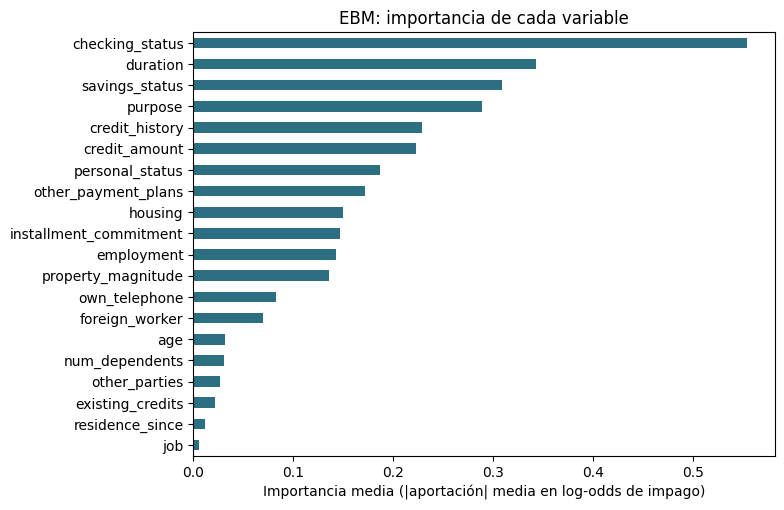

Intercepto (punto de partida de todos): -1.135


In [6]:
exp = model.explain_global()
imp = pd.Series(model.term_importances(), index=model.term_names_).sort_values(ascending=False)
storage_csv(imp.rename("importancia").to_frame(), "importancia")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
imp[::-1].plot.barh(ax=ax, color="#2b6f80")
ax.set_xlabel("Importancia media (|aportación| media en log-odds de impago)")
ax.set_title("EBM: importancia de cada variable")
storage("2_3", "importancia")
print(f"Intercepto (punto de partida de todos): {model.intercept_[0]:.3f}")

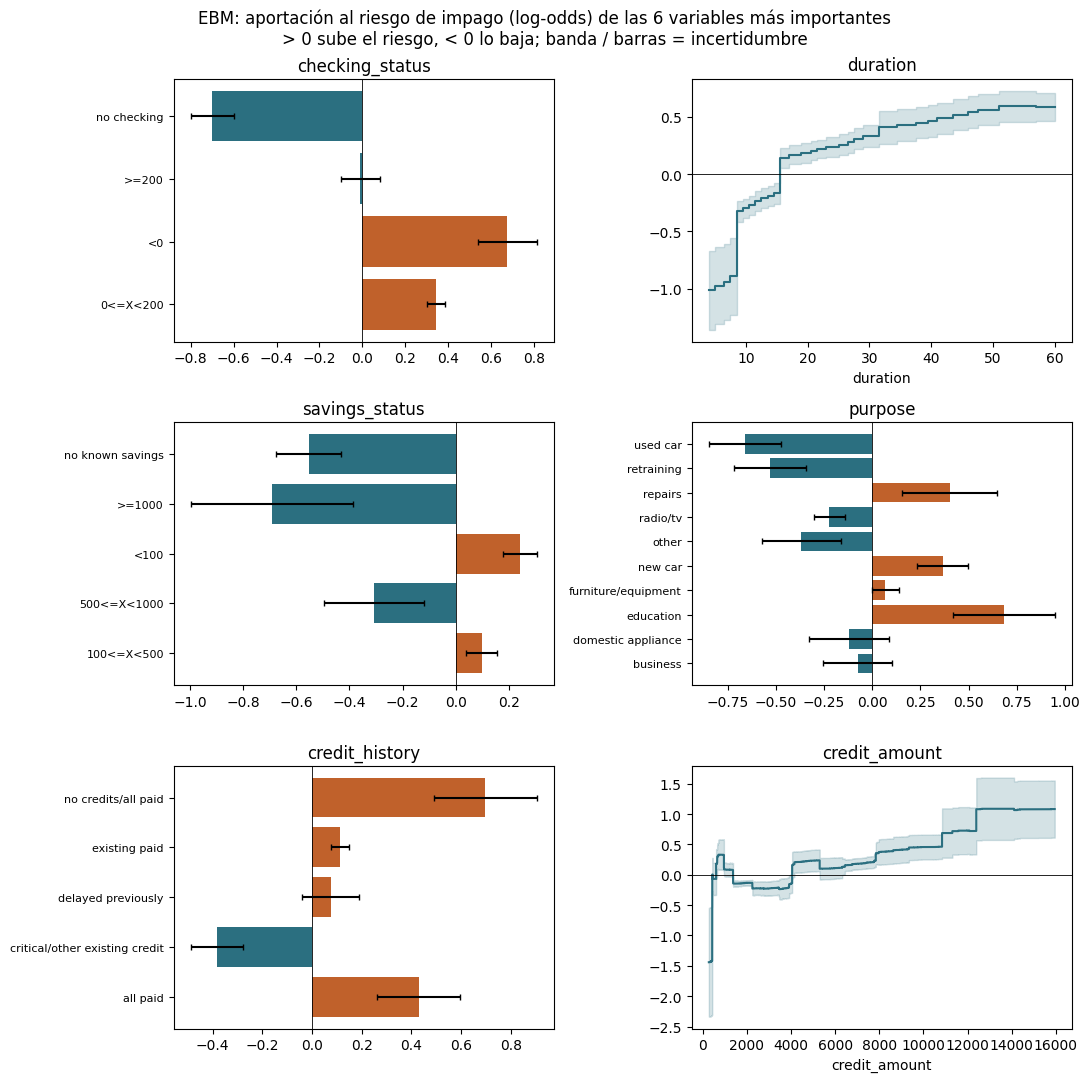

In [7]:
NUM, CAT = pc.columns(X_train)
curvas = []
for i, var in enumerate(model.term_names_):
    if " & " in var:
        continue
    d = exp.data(i)
    if var in NUM:
        c = np.asarray(d["names"])
        valores = [f"{c[j]:g} a {c[j + 1]:g}" for j in range(len(d["scores"]))]
    else:
        valores = list(d["names"])
    curvas.append(pd.DataFrame({"variable": var, "valor": valores, "aporte": d["scores"],
                                "inferior": d["lower_bounds"], "superior": d["upper_bounds"]}))
curvas = pd.concat(curvas, ignore_index=True)
storage_csv(curvas, "curvas", index=False)

top6 = [v for v in imp.index if " & " not in v][:6]
fig, axes = plt.subplots(3, 2, figsize=(11, 11))
for ax, var in zip(axes.ravel(), top6):
    d = exp.data(model.term_names_.index(var))
    if var in NUM:
        c = np.asarray(d["names"]); x = np.repeat(c, 2)[1:-1]
        ax.plot(x, np.repeat(d["scores"], 2), color="#2b6f80")
        ax.fill_between(x, np.repeat(d["lower_bounds"], 2), np.repeat(d["upper_bounds"], 2), color="#2b6f80", alpha=0.2)
        ax.axhline(0, color="black", lw=0.6); ax.set_xlabel(var)
    else:
        s = np.asarray(d["scores"])
        err = [s - np.asarray(d["lower_bounds"]), np.asarray(d["upper_bounds"]) - s]
        ax.barh(list(d["names"]), s, xerr=err, capsize=2.5, color=["#c0612b" if v > 0 else "#2b6f80" for v in s])
        ax.axvline(0, color="black", lw=0.6); ax.tick_params(axis="y", labelsize=8)
    ax.set_title(var)
fig.suptitle("EBM: aportación al riesgo de impago (log-odds) de las 6 variables más importantes\n"
             "> 0 sube el riesgo, < 0 lo baja; banda / barras = incertidumbre")
plt.tight_layout()
storage("2_3", "curvas_top6")

## 5. Estabilidad de la explicación

Reentreno el EBM en cada partición de la validación cruzada (15 veces, cada vez con un 80 % distinto del entrenamiento) y mido con `pc.stability` si el **top-5 de variables** se mantiene (Jaccard medio entre todos los pares: 1 = siempre las mismas). Además comparo las curvas de cada reentrenamiento con las del modelo final.

In [8]:
contrib_final = model.eval_terms(X_train)
tops, contribs = [], []
for tr, va in pc.CV.split(X_train, y_train):
    m = ebm(INTER)().fit(X_train.iloc[tr], y_train.iloc[tr])
    tops.append(list(pd.Series(m.term_importances(), index=m.term_names_).nlargest(5).index))
    contribs.append(m.eval_terms(X_train))
contribs = np.array(contribs)

STABILITY = pc.stability(tops)
first = pd.Series([t[0] for t in tops]).value_counts()
parecido = pd.Series([np.mean([np.corrcoef(contribs[k, :, j], contrib_final[:, j])[0, 1] for k in range(len(contribs))])
                      for j in range(len(model.term_names_))], index=model.term_names_)[imp.index]
storage_csv(pd.DataFrame({"importancia": imp, "correlacion_curva_con_final": parecido}), "estabilidad")
print(f"Jaccard medio del top-5 entre reentrenamientos: {STABILITY:.2f}")
print(f"Variable más importante en cada reentrenamiento: {dict(first)}")
print("\nParecido de cada curva con la del modelo final (1 = idéntica):")
print(parecido.round(2).to_string())

Jaccard medio del top-5 entre reentrenamientos: 0.75
Variable más importante en cada reentrenamiento: {'checking_status': np.int64(15)}

Parecido de cada curva con la del modelo final (1 = idéntica):
checking_status           0.99
duration                  0.99
savings_status            0.98
purpose                   0.96
credit_history            0.98
credit_amount             0.89
personal_status           0.97
other_payment_plans       0.98
housing                   0.96
installment_commitment    0.99
employment                0.94
property_magnitude        0.96
own_telephone             1.00
foreign_worker            1.00
age                       0.77
num_dependents            1.00
other_parties             0.84
existing_credits          0.55
residence_since           0.14
job                       0.22


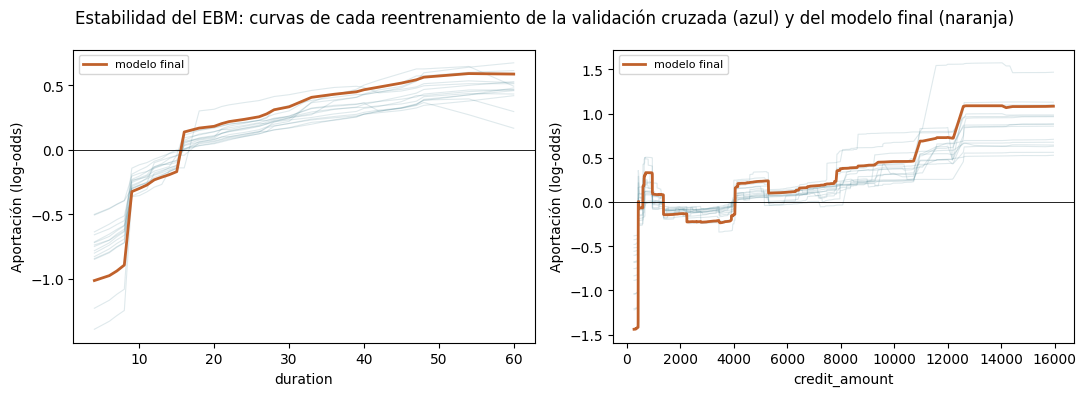

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, var in zip(axes, ["duration", "credit_amount"]):
    j = list(model.term_names_).index(var)
    o = np.argsort(X_train[var].values)
    xs = X_train[var].values[o]
    for k in range(len(contribs)):
        ax.plot(xs, contribs[k, o, j], color="#2b6f80", alpha=0.15, lw=0.8)
    ax.plot(xs, contrib_final[o, j], color="#c0612b", lw=2, label="modelo final")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xlabel(var); ax.set_ylabel("Aportación (log-odds)"); ax.legend(fontsize=8)
fig.suptitle("Estabilidad del EBM: curvas de cada reentrenamiento de la validación cruzada (azul) y del modelo final (naranja)")
plt.tight_layout()
storage("2_3", "estabilidad_curvas")

## 6. Solicitantes concretos

En el EBM la explicación de una decisión es **exacta**: punto de partida + aportación de cada variable = puntuación (log-odds), y la función logística la convierte en probabilidad. Se puede hacer a mano.

Propuesta de solicitantes del test (hay que cerrarla con Persona 3 y el subgrupo B para que sean **los mismos en todos los modelos**): el buen pagador con menor riesgo (aprobado claro), el impago con mayor riesgo (denegado claro) y el más cercano al umbral (dudoso). Si se eligen otros, basta con cambiar `CASOS`.

In [10]:
t = pd.DataFrame({"y": y_test, "p": p_test}, index=X_test.index)
CASOS = {"aprobado": t[t.y == 0].p.idxmin(),
         "denegado": t[t.y == 1].p.idxmax(),
         "dudoso": (t.p - thres).abs().idxmin()}
print("Índices propuestos (fila del dataset, empezando en 0):", CASOS)

Índices propuestos (fila del dataset, empezando en 0): {'aprobado': np.int64(159), 'denegado': np.int64(832), 'dudoso': np.int64(977)}



===== APROBADO (fila 159) · impago real: no =====
              variable                          valor  aporte
              duration                              6   -0.97
       checking_status                    no checking   -0.70
        savings_status               no known savings   -0.55
        credit_history critical/other existing credit   -0.38
installment_commitment                              1   -0.24
               purpose                       radio/tv   -0.22
    property_magnitude                    real estate   -0.21
       personal_status                    male single   -0.17
... resto: -0.17
z = -1.13 + -3.63 = -4.77  ->  p = 1/(1+e^(4.77)) = 0.008  (modelo: 0.008)  ->  umbral 0.17: CONCEDER

===== DENEGADO (fila 832) · impago real: sí =====
              variable               valor  aporte
         credit_amount               11816   +0.73
        credit_history no credits/all paid   +0.70
       checking_status                  <0   +0.68
              dur

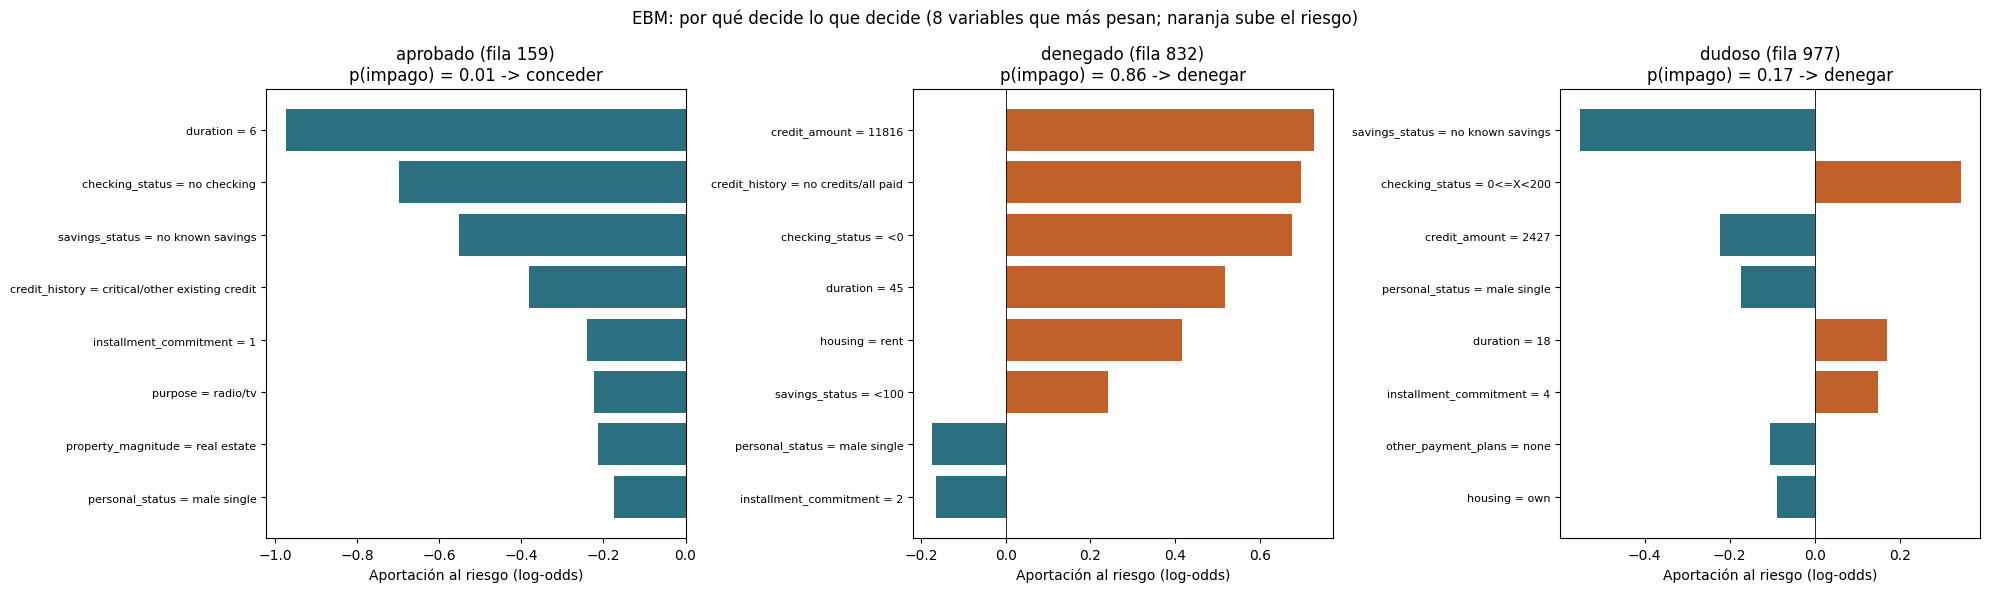

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (name, idx) in zip(axes, CASOS.items()):
    row = X_test.loc[[idx]]
    a = model.eval_terms(row)[0]
    valor = [" / ".join(str(row[v].iloc[0]) for v in var.split(" & ")) for var in model.term_names_]
    tab = pd.DataFrame({"variable": model.term_names_, "valor": valor, "aporte": a})
    tab = tab.reindex(np.argsort(-np.abs(a)))
    storage_csv(tab, f"caso_{name}", index=False)

    z = model.intercept_[0] + a.sum()
    p = 1 / (1 + np.exp(-z))
    decision = "denegar" if p >= thres else "conceder"

    print(f"\n===== {name.upper()} (fila {idx}) · impago real: {'sí' if y_test.loc[idx] else 'no'} =====")
    print(tab.head(8).to_string(index=False, float_format="%+.2f"))
    print(f"... resto: {tab.aporte[8:].sum():+.2f}")
    print(f"z = {model.intercept_[0]:+.2f} + {a.sum():+.2f} = {z:+.2f}  ->  p = 1/(1+e^({-z:.2f})) = {p:.3f}"
          f"  (modelo: {model.predict_proba(row)[0, 1]:.3f})  ->  umbral {thres}: {decision.upper()}")

    top = tab.head(8).iloc[::-1]
    ax.barh([f"{v} = {w}" for v, w in zip(top.variable, top.valor)], top.aporte,
            color=["#c0612b" if x > 0 else "#2b6f80" for x in top.aporte])
    ax.axvline(0, color="black", lw=0.6); ax.tick_params(axis="y", labelsize=8)
    ax.set_xlabel("Aportación al riesgo (log-odds)")
    ax.set_title(f"{name} (fila {idx})\np(impago) = {p:.2f} -> {decision}")
fig.suptitle("EBM: por qué decide lo que decide (8 variables que más pesan; naranja sube el riesgo)")
plt.tight_layout()
storage("4_1", "casos")

## 7. Sesgos por edad en los dos modelos de A

Atributo protegido: **edad** (≤25 frente a >25 años, `pc.CUTOFF_AGE`). Resultado favorable para el cliente: que se le **conceda** el crédito. Uso `pc.equity` (tasa de concesión, buenos denegados y malos detectados por grupo):

- Diferencia en **tasa de concesión** → paridad demográfica (y su cociente, que la regla de los 4/5 pide ≥ 0,8).
- Diferencia en **malos detectados** → igualdad de oportunidades.
- Diferencias en **malos detectados y buenos denegados** → *equalized odds*.

Lo calculo en el test (el que se guarda para la comparación) y también con las predicciones fuera de muestra de la validación cruzada (800 casos, más fiable, porque en el test hay pocos jóvenes).

La **logística** se reentrena aquí exactamente igual que en `A_logistica.ipynb` (mismas categorías de referencia y mismo C). Si Persona 1 cambia algo, hay que cambiarlo aquí también.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

C_LOG = 0.3
REFERENCIAS = {
    "checking_status": "<0", "credit_history": "no credits/all paid", "purpose": "new car",
    "savings_status": "<100", "employment": "unemployed", "personal_status": "male div/sep",
    "other_parties": "none", "property_magnitude": "real estate", "other_payment_plans": "bank",
    "housing": "rent", "job": "unemp/unskilled non res", "own_telephone": "none", "foreign_worker": "yes",
}

def logistic(drop_age=False):
    def create():
        num_, cat_ = pc.columns(X_train.drop(columns="age") if drop_age else X_train)
        prep = ColumnTransformer([
            ("num", StandardScaler(), num_),
            ("cat", OneHotEncoder(drop=[REFERENCIAS[c] for c in cat_], handle_unknown="ignore", sparse_output=False), cat_)])
        return Pipeline([("prep", prep), ("lr", LogisticRegression(C=C_LOG, max_iter=5000))])
    return create

def ratio(t):
    young = t.loc[f"≤{pc.CUTOFF_AGE} años", "Tasa de concesión"]
    old = t.loc[f">{pc.CUTOFF_AGE} años", "Tasa de concesión"]
    return young / old

In [13]:
modelos = {"Logística": logistic(), "EBM": ebm(INTER)}
equidad = {}
for name, create in modelos.items():
    if name == "EBM":
        tcv, th, oo = table_cv, thres, oof
    else:
        tcv, th, oo = pc.evaluate_csv(create, X_train, y_train)
    pt = create().fit(X_train, y_train).predict_proba(X_test)[:, 1]
    e_test = pc.equity(y_test, pt, X_test["age"], th)
    e_cv = pc.equity(y_train, oo, X_train["age"], th)
    equidad[name] = (e_test, e_cv, th, tcv)

    if name == "EBM":
        pc.storage_equity(FOLDER, "A", "EBM", e_test)
    clave = "logistica" if name == "Logística" else "EBM"
    e_cv.assign(modelo=name).to_csv(os.path.join(R["results"], f"equidad_cv_A_{clave}.csv"))

    print(f"\n===== {name} (umbral {th}) =====")
    print("Test:"); print(e_test.round(3).to_string())
    print(f"Cociente de concesión jóvenes/mayores: {ratio(e_test):.2f}")
    print("Validación cruzada (fuera de muestra):"); print(e_cv.round(3).to_string())
    print(f"Cociente de concesión jóvenes/mayores: {ratio(e_cv):.2f}")


===== Logística (umbral 0.2) =====
Test:
               Tasa de concesión  Buenos denegados  Malos detectados      n
grupo de edad                                                              
>25 años                   0.436             0.457             0.875  156.0
≤25 años                   0.295             0.583             0.850   44.0
diferencia                 0.140             0.126             0.025    NaN
Cociente de concesión jóvenes/mayores: 0.68
Validación cruzada (fuera de muestra):
               Tasa de concesión  Buenos denegados  Malos detectados      n
grupo de edad                                                              
>25 años                   0.459             0.422             0.856  654.0
≤25 años                   0.274             0.605             0.900  146.0
diferencia                 0.185             0.183             0.044    NaN
Cociente de concesión jóvenes/mayores: 0.60

===== EBM (umbral 0.17) =====
Test:
               Tasa de concesión  

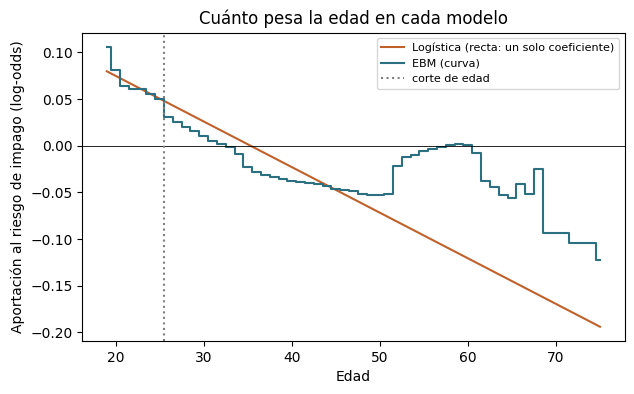

Logística: odds x 0.95 por cada 10 años más
EBM: aporte a los 20 años +0.08, a los 30 +0.01, a los 50 -0.05


In [14]:
lr = logistic()().fit(X_train, y_train)
names = list(lr.named_steps["prep"].get_feature_names_out())
beta_age = lr.named_steps["lr"].coef_[0][names.index("num__age")]
sd_age = X_train["age"].std(ddof=0)
ages = np.arange(19, 76)
rows = pd.concat([X_train.iloc[[0]]] * len(ages), ignore_index=True)
rows["age"] = ages
a_ebm = model.eval_terms(rows)[:, list(model.term_names_).index("age")]
a_lr = beta_age * (ages - X_train["age"].mean()) / sd_age

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ages, a_lr, color="#c0612b", label="Logística (recta: un solo coeficiente)")
ax.step(ages, a_ebm, where="mid", color="#2b6f80", label="EBM (curva)")
ax.axhline(0, color="black", lw=0.6)
ax.axvline(pc.CUTOFF_AGE + 0.5, ls=":", color="gray", label="corte de edad")
ax.set_xlabel("Edad"); ax.set_ylabel("Aportación al riesgo de impago (log-odds)")
ax.set_title("Cuánto pesa la edad en cada modelo"); ax.legend(fontsize=8)
storage("4_2", "edad_en_modelos")
print(f"Logística: odds x {np.exp(beta_age / sd_age * 10):.2f} por cada 10 años más")
print(f"EBM: aporte a los 20 años {a_ebm[ages == 20][0]:+.2f}, a los 30 {a_ebm[ages == 30][0]:+.2f}, a los 50 {a_ebm[ages == 50][0]:+.2f}")

In [15]:
Xtr_s = X_train.drop(columns="age")
rows = []
for name, create in {"Logística": logistic(drop_age=True), "EBM": ebm(INTER)}.items():
    tcv_s, th_s, oo_s = pc.evaluate_csv(create, Xtr_s, y_train)
    e_s = pc.equity(y_train, oo_s, X_train["age"], th_s)
    e_test, e_cv, th, tcv = equidad[name]
    for version, t_, e_ in [("con edad", tcv, e_cv), ("sin edad", tcv_s, e_s)]:
        rows.append({"modelo": name, "versión": version,
                     "AUC CV": t_["AUC"].mean(), "Coste CV": t_["Coste medio"].mean(),
                     "dif. concesión": e_.loc["diferencia", "Tasa de concesión"],
                     "cociente concesión": ratio(e_),
                     "dif. buenos denegados": e_.loc["diferencia", "Buenos denegados"],
                     "dif. malos detectados": e_.loc["diferencia", "Malos detectados"]})
sin_edad = pd.DataFrame(rows)
storage_csv(sin_edad, "sin_edad", index=False)
sin_edad.round(3)

,modelo,versión,AUC CV,Coste CV,dif. concesión,cociente concesión,dif. buenos denegados,dif. malos detectados
0,Logística,con edad,0.777,0.531,0.185,0.597,0.183,0.044
1,Logística,sin edad,0.778,0.524,0.171,0.616,0.170,0.028
2,EBM,con edad,0.780,0.543,0.214,0.424,0.213,0.100
3,EBM,sin edad,0.783,0.535,0.204,0.501,0.203,0.078


## 8. Auditoría
Respuesta del EBM a cada pregunta de `pc.AUDIT_LIST`, con su evidencia de este cuaderno.

In [16]:
for i, q in enumerate(pc.AUDIT_LIST):
    print(q)

1. ¿Se puede reproducir una decisión concreta a mano o con una fórmula documentada?
2. ¿Se puede revisar el modelo completo con un número manejable de elementos (coeficientes, reglas, nodos)?
3. ¿La explicación sale del propio modelo o de una aproximación externa?
4. ¿La explicación es estable entre ejecuciones o particiones (Jaccard del top-5)?
5. ¿Se puede ver qué peso tienen las variables sensibles o sus aproximaciones (edad, estado civil)?
6. ¿Se puede comprobar la equidad por grupos de edad?
7. ¿Se puede detectar un comportamiento ilógico del modelo (efectos contraintuitivos)?
8. ¿Puede el solicitante recibir una explicación útil y accionable (qué tendría que cambiar)?
9. ¿Está documentado con una model card completa?


In [17]:
audit = [
    ("Sí", "La decisión es intercepto + suma de las aportaciones de las 20 variables, convertida con la función logística. Se reproduce a mano y coincide con el modelo (4.1: p = 0,008, 0,856 y 0,175)."),
    ("Sí", f"{len(model.term_names_)} curvas, una por variable, sin interacciones (elegidas con la regla de una desviación típica). Se pueden dibujar y revisar todas."),
    ("Sí", "La explicación es el propio modelo (glassbox): no hay ninguna aproximación externa como LIME o SHAP."),
    ("Sí", f"Jaccard medio del top-5 entre 15 reentrenamientos = {STABILITY:.2f}; checking_status es la primera las 15 veces. Las curvas son inestables solo donde hay pocos datos (importes > 10.000 DM)."),
    ("Sí", "Se ve directamente la curva de la edad (aporta +0,08 a los 20 años y -0,05 a los 50) y la de las variables relacionadas (estado civil, empleo, vivienda)."),
    ("Sí", f"Con pc.equity: cociente de concesión jóvenes/mayores {ratio(equidad['EBM'][1]):.2f} en validación cruzada, por debajo de 0,8. Quitar la edad no lo arregla (proxies)."),
    ("Sí", "Las curvas muestran efectos contraintuitivos: el historial 'critical/other existing credit' baja el riesgo (errores de codificación, Grömping 2019) y afecta a decisiones concretas (solicitante 159)."),
    ("Parcial", "Se ve qué variables suben el riesgo y cuánto, pero el modelo no da directamente qué cambiar, y algunas variables no se pueden cambiar (edad, estado civil)."),
    ("Sí", "Model card del EBM en el apartado 4.3 de la wiki."),
]
pc.storage_auditory(FOLDER, "A", "EBM", audit)

,valoración,evidencia
pregunta,,
1. ¿Se puede reproducir una decisión concreta a mano o con una fórmula documentada?,Sí,La decisión es intercepto + suma de las aporta...
"2. ¿Se puede revisar el modelo completo con un número manejable de elementos (coeficientes, reglas, nodos)?",Sí,"20 curvas, una por variable, sin interacciones..."
3. ¿La explicación sale del propio modelo o de una aproximación externa?,Sí,La explicación es el propio modelo (glassbox):...
4. ¿La explicación es estable entre ejecuciones o particiones (Jaccard del top-5)?,Sí,Jaccard medio del top-5 entre 15 reentrenamien...
"5. ¿Se puede ver qué peso tienen las variables sensibles o sus aproximaciones (edad, estado civil)?",Sí,Se ve directamente la curva de la edad (aporta...
6. ¿Se puede comprobar la equidad por grupos de edad?,Sí,Con pc.equity: cociente de concesión jóvenes/m...
7. ¿Se puede detectar un comportamiento ilógico del modelo (efectos contraintuitivos)?,Sí,Las curvas muestran efectos contraintuitivos: ...
8. ¿Puede el solicitante recibir una explicación útil y accionable (qué tendría que cambiar)?,Parcial,"Se ve qué variables suben el riesgo y cuánto, ..."
9. ¿Está documentado con una model card completa?,Sí,Model card del EBM en el apartado 4.3 de la wiki.
